### 1. Assignment -10-

**Ensemble Learning for Survival Prediction**

### 2. Context & Scenario

You are working on a machine learning systems team at a transportation analytics organization. The team needs a binary classifier that predicts passenger survival from structured manifest data and must justify both predictive quality and operational reliability. Your task is to compare a baseline linear model with several ensemble methods and determine whether the additional complexity is justified. In addition to accuracy, you must consider calibration, reproducibility, leakage prevention, runtime cost, and post-deployment monitoring. Your final recommendation should reflect both model performance and systems constraints.

### 3. Dataset

**Dataset name:** Titanic (OpenML)

**Access links:**  
- OpenML dataset page: `https://www.openml.org/d/40945`  
- Python load path: `sklearn.datasets.fetch_openml(name="titanic", version=1, as_frame=True)`

This dataset contains passenger-level records from the Titanic, with structured features such as passenger class, sex, age, fare, cabin, and embarkation details. The unit of analysis is an individual passenger, and the target is binary survival outcome. The dataset contains approximately 1,300 rows and mixed numeric/categorical predictors, making it suitable for preprocessing pipelines and ensemble comparison.


### 4. Machine Learning Tasks

- Load the dataset programmatically and record basic dataset metadata.
- Validate schema, missingness, duplicates, class balance, and add at least one guardrail assertion.
- Perform EDA with summary statistics and at least one matplotlib visualization.
- Build a leakage-safe preprocessing pipeline with numeric scaling and an optional transform where justified.
- Train a logistic-regression baseline and compare it with voting, bagging, random forest, boosting, and stacking models.
- Evaluate models using hold-out and cross-validation metrics, confusion matrix, ROC curve, calibration-oriented metrics, and permutation importance.
- Interpret results and justify model selection using evidence rather than raw accuracy alone.
- Discuss ML-systems implications, including reproducibility, latency, and monitoring.

### 5. Deliverables

- One executed Jupyter notebook with code, plots, and brief written responses.
- Embedded markdown reflections interpreting model behavior and systems tradeoffs.
- A final recommendation identifying the most appropriate model for deployment.
- Proper dataset citation.

### 6. Grading Rubric (100 points)

| Criterion | Points | Description |
|---|---:|---|
| Code correctness | 25 | Notebook runs end-to-end; code is correct and complete. |
| Data quality and validation | 15 | Schema checks, missingness handling, duplicates, class balance, and guardrails are appropriate. |
| EDA | 10 | Visualizations and descriptive analysis are clear and relevant. |
| Modeling and evaluation | 25 | Baseline and ensemble comparisons are implemented correctly with appropriate metrics and diagnostics. |
| Interpretation | 15 | Conclusions are evidence-based, concise, and technically sound. |
| ML-systems thinking | 10 | Reproducibility and monitoring, driftare addressed clearly. |


______________________________________________________________________________________________________________________________________________

# Assignment 10 - Ensemble Learning for Survival Prediction

## Context & Scenario

The goal is to predict passenger survival from structured Titanic manifest data. A logistic regression model is used as the baseline and is compared with voting, bagging, random forest, boosting, and stacking models. The comparison focuses on more than accuracy by also considering ROC AUC, precision, recall, F1 score, calibration, runtime, and model complexity.

In [40]:
# Imports and reproducibility

import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    VotingClassifier,
    BaggingClassifier,
    RandomForestClassifier,
    HistGradientBoostingClassifier,
    StackingClassifier
)

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    log_loss,
    brier_score_loss,
    roc_curve
)

from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

print("Python:", sys.version)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Random state:", RANDOM_STATE)

Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
pandas: 2.3.3
NumPy: 2.5.3
Random state: 42


## Load Dataset

The Titanic dataset is loaded directly from OpenML using fetch_openml. This keeps the data loading process reproducible.

In [41]:
titanic = fetch_openml(
    name="titanic",
    version=1,
    as_frame=True
)

df = titanic.frame.copy()

print("Dataset shape:", df.shape)
print("Dataset type:", type(df))

display(df.head())

Dataset shape: (1309, 14)
Dataset type: <class 'pandas.core.frame.DataFrame'>


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


In [42]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nTarget values:")
print(df["survived"].value_counts(dropna=False))

Rows: 1309
Columns: 14

Column names:
['pclass', 'survived', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket', 'fare', 'cabin', 'embarked', 'boat', 'body', 'home.dest']

Data types:
pclass          int64
survived     category
name           object
sex          category
age           float64
sibsp           int64
parch           int64
ticket         object
fare          float64
cabin          object
embarked     category
boat           object
body          float64
home.dest      object
dtype: object

Target values:
survived
0    809
1    500
Name: count, dtype: int64


## Data Validation

The dataset is checked for unexpected target values, missing values, duplicate rows, and class balance. These checks help identify problems before the modeling pipeline is created.

In [43]:
missing_values = df.isna().sum()

missing_table = pd.DataFrame({
    "missing_count": missing_values,
    "missing_percent": (missing_values / len(df)) * 100
})

display(
    missing_table.sort_values(
        "missing_count",
        ascending=False
    )
)

,missing_count,missing_percent
body,1188,90.756303
cabin,1014,77.463713
boat,823,62.872422
home.dest,564,43.086325
age,263,20.091673
embarked,2,0.152788
fare,1,0.076394
sibsp,0,0.000000
name,0,0.000000
survived,0,0.000000


In [44]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [45]:
# Target validation and class balance

print("Survival distribution:")
print(df["survived"].value_counts())

print("\nSurvival proportions:")
print(df["survived"].value_counts(normalize=True))

Survival distribution:
survived
0    809
1    500
Name: count, dtype: int64

Survival proportions:
survived
0    0.618029
1    0.381971
Name: proportion, dtype: float64


In [74]:
# Guardrail checks

assert len(df) > 1000, "Dataset contains unexpectedly few rows."
assert df["survived"].notna().all(), "Target contains missing values."
assert set(df["survived"].astype(str).unique()).issubset({"0", "1"}), \
    "Unexpected target values found."

print("All guardrail checks passed.")

All guardrail checks passed.


## Exploratory Data Analysis

The target distribution is examined first to understand the class balance before evaluating model performance. Passenger class and sex are also compared with survival because they show clear differences in survival rates.

In [47]:
# Summary statistics

display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
pclass,1309.0,NaN,NaN,NaN,2.294882,0.837836,1.0,2.0,3.0,3.0,3.0
survived,1309,2,0,809,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,1309,1307,"Connolly, Miss. Kate",2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,1309,2,male,843,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1046.0,NaN,NaN,NaN,29.881135,14.4135,0.1667,21.0,28.0,39.0,80.0
sibsp,1309.0,NaN,NaN,NaN,0.498854,1.041658,0.0,0.0,0.0,1.0,8.0
parch,1309.0,NaN,NaN,NaN,0.385027,0.86556,0.0,0.0,0.0,0.0,9.0
ticket,1309,929,CA. 2343,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fare,1308.0,NaN,NaN,NaN,33.295479,51.758668,0.0,7.8958,14.4542,31.275,512.3292
cabin,295,186,C23 C25 C27,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN


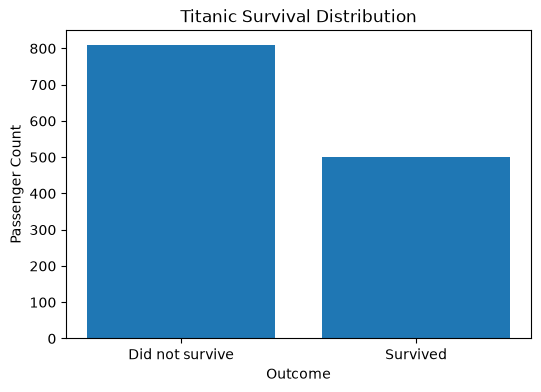

In [48]:
# Survival distribution

survival_counts = df["survived"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(
    ["Did not survive", "Survived"],
    survival_counts.values
)
plt.title("Titanic Survival Distribution")
plt.xlabel("Outcome")
plt.ylabel("Passenger Count")
plt.show()

In [49]:
# Survival rate by passenger class

class_survival = pd.crosstab(
    df["pclass"],
    df["survived"],
    normalize="index"
)

display(class_survival)

survived,0,1
pclass,,
1,0.380805,0.619195
2,0.570397,0.429603
3,0.744711,0.255289


In [50]:
# Survival rate by sex

sex_survival = pd.crosstab(
    df["sex"],
    df["survived"],
    normalize="index"
)

display(sex_survival)

survived,0,1
sex,,
female,0.272532,0.727468
male,0.809015,0.190985


## Feature Preparation

The target is converted to an integer binary variable. Identifier-like columns are excluded from modeling when they do not provide useful predictive information. The remaining numeric and categorical features are handled separately by the preprocessing pipeline.

In [51]:
# Convert target to integer

df["survived"] = df["survived"].astype(int)

# Remove target

X = df.drop(columns=["survived"]).copy()
y = df["survived"].copy()

print("Features:", X.shape)
print("Target:", y.shape)

Features: (1309, 13)
Target: (1309,)


In [52]:
columns_to_drop = []

for column in ["name", "ticket", "cabin", "home.dest", "boat"]:
    if column in X.columns:
        columns_to_drop.append(column)

X = X.drop(columns=columns_to_drop)

print("Dropped columns:", columns_to_drop)
print("Remaining columns:")
print(X.columns.tolist())

Dropped columns: ['name', 'ticket', 'cabin', 'home.dest', 'boat']
Remaining columns:
['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'body']


In [53]:
# Identify numeric and categorical columns

numeric_features = X.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['pclass', 'age', 'sibsp', 'parch', 'fare', 'body']

Categorical features:
['sex', 'embarked']


In [54]:
# Stratified train/test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining class balance:")
print(y_train.value_counts(normalize=True))

print("\nTesting class balance:")
print(y_test.value_counts(normalize=True))

Training rows: 1047
Testing rows: 262

Training class balance:
survived
0    0.617956
1    0.382044
Name: proportion, dtype: float64

Testing class balance:
survived
0    0.618321
1    0.381679
Name: proportion, dtype: float64


## Preprocessing Pipeline

Preprocessing is placed inside a scikit-learn pipeline so that imputation, scaling, and one-hot encoding are learned only from the training data. This prevents information from the test set from entering the model.

In [55]:
# Preprocessing pipelines

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [56]:
# Logistic regression baseline

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

start_time = time.perf_counter()

logistic_model.fit(X_train, y_train)

logistic_train_time = time.perf_counter() - start_time

print("Logistic regression training time:",
      round(logistic_train_time, 4), "seconds")

Logistic regression training time: 0.0104 seconds


In [57]:
# Voting classifier

voting_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", VotingClassifier(
        estimators=[
            ("logistic", LogisticRegression(
                max_iter=1000,
                random_state=RANDOM_STATE
            )),
            ("tree", DecisionTreeClassifier(
                max_depth=5,
                random_state=RANDOM_STATE
            )),
            ("rf", RandomForestClassifier(
                n_estimators=100,
                max_depth=6,
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ],
        voting="soft"
    ))
])

In [58]:
# Bagging classifier

bagging_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", BaggingClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=5,
            random_state=RANDOM_STATE
        ),
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

In [59]:
# Random forest

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

In [60]:
# HistGradientBoosting

boosting_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.05,
        max_leaf_nodes=15,
        random_state=RANDOM_STATE
    ))
])

In [61]:
# Stacking classifier

stacking_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", StackingClassifier(
        estimators=[
            ("logistic", LogisticRegression(
                max_iter=1000,
                random_state=RANDOM_STATE
            )),
            ("rf", RandomForestClassifier(
                n_estimators=100,
                max_depth=6,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )),
            ("tree", DecisionTreeClassifier(
                max_depth=5,
                random_state=RANDOM_STATE
            ))
        ],
        final_estimator=LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        ),
        cv=5
    ))
])

In [62]:
# Store models

models = {
    "Logistic Regression": logistic_model,
    "Voting": voting_model,
    "Bagging": bagging_model,
    "Random Forest": random_forest_model,
    "Boosting": boosting_model,
    "Stacking": stacking_model
}

# Train models and record runtime

training_times = {}

for name, model in models.items():

    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    training_times[name] = time.perf_counter() - start_time

    print(
        name,
        "trained in",
        round(training_times[name], 4),
        "seconds"
    )

Logistic Regression trained in 0.0082 seconds
Voting trained in 0.09 seconds
Bagging trained in 0.21 seconds
Random Forest trained in 0.2471 seconds
Boosting trained in 0.1573 seconds
Stacking trained in 0.6028 seconds


In [63]:
# Evaluate models on the test set

results = []

for name, model in models.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC AUC": roc_auc_score(y_test, probabilities),
        "Log Loss": log_loss(y_test, probabilities),
        "Brier Score": brier_score_loss(y_test, probabilities),
        "Training Time": training_times[name]
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "ROC AUC",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1,ROC AUC,Log Loss,Brier Score,Training Time
0,Boosting,0.828244,0.802198,0.73,0.764398,0.913457,0.376387,0.114327,0.157273
1,Bagging,0.839695,0.862500,0.69,0.766667,0.904691,0.389370,0.116185,0.209966
2,Random Forest,0.839695,0.829545,0.73,0.776596,0.903426,0.380260,0.115497,0.247136
3,Stacking,0.843511,0.831461,0.74,0.783069,0.897623,0.379612,0.114922,0.602764
4,Voting,0.835878,0.813187,0.74,0.774869,0.895154,0.384488,0.117092,0.090022
5,Logistic Regression,0.809160,0.771739,0.71,0.739583,0.866883,0.433353,0.135343,0.008191


## Cross-Validation

A stratified five-fold cross-validation procedure is used to check whether the hold-out results are consistent across different training subsets. Mean and standard deviation are reported because a model with slightly higher average performance but very unstable results may be less desirable.

In [64]:
# Five-fold cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

for name, model in models.items():

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy SD": scores["test_accuracy"].std(),
        "F1 Mean": scores["test_f1"].mean(),
        "F1 SD": scores["test_f1"].std(),
        "ROC AUC Mean": scores["test_roc_auc"].mean(),
        "ROC AUC SD": scores["test_roc_auc"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.sort_values(
        "ROC AUC Mean",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy Mean,Accuracy SD,F1 Mean,F1 SD,ROC AUC Mean,ROC AUC SD
0,Boosting,0.814366,0.023320,0.742930,0.033010,0.878377,0.030495
1,Random Forest,0.817417,0.027145,0.738121,0.041199,0.867172,0.028449
2,Bagging,0.810544,0.032161,0.727727,0.047844,0.864952,0.033319
3,Voting,0.806721,0.024700,0.733261,0.038507,0.864897,0.023372
4,Logistic Regression,0.788392,0.010612,0.713685,0.020821,0.840851,0.026860
5,Stacking,0.791463,0.017640,0.688522,0.028559,0.821854,0.038434


In [65]:
# Select best model

best_model_name = cv_results_df.sort_values(
    "ROC AUC Mean",
    ascending=False
).iloc[0]["Model"]

best_model = models[best_model_name]

print("Best model:", best_model_name)

Best model: Boosting


[[144  18]
 [ 27  73]]


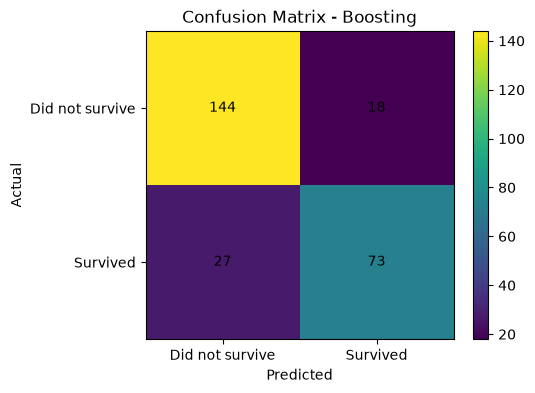

In [66]:
# Confusion matrix

best_predictions = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    best_predictions
)

print(cm)

plt.figure(figsize=(5, 4))
plt.imshow(cm)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Did not survive", "Survived"])
plt.yticks([0, 1], ["Did not survive", "Survived"])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()

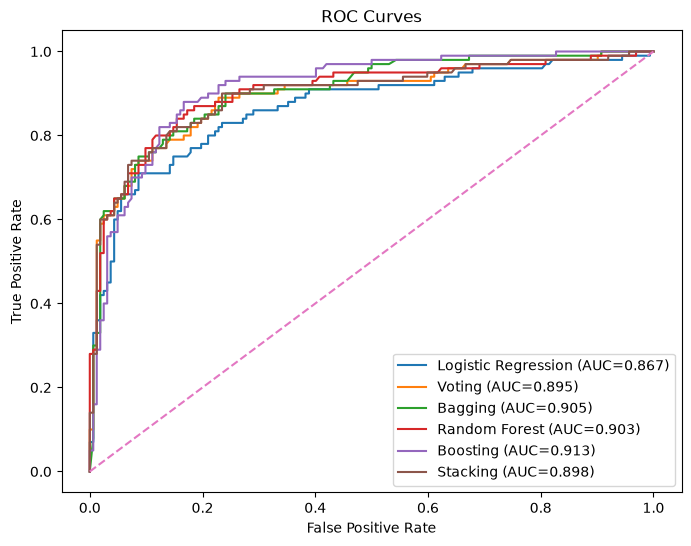

In [67]:
# ROC curves

plt.figure(figsize=(8, 6))

for name, model in models.items():

    probabilities = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

## Calibration

A survival model produces probabilities, so calibration is important in addition to classification accuracy. Brier score and log loss are used to measure the quality of the predicted probabilities. Lower values are better.

In [68]:
# Calibration metrics

calibration_results = []

for name, model in models.items():

    probabilities = model.predict_proba(X_test)[:, 1]

    calibration_results.append({
        "Model": name,
        "Brier Score": brier_score_loss(
            y_test,
            probabilities
        ),
        "Log Loss": log_loss(
            y_test,
            probabilities
        )
    })

calibration_df = pd.DataFrame(
    calibration_results
)

display(
    calibration_df.sort_values(
        "Brier Score"
    ).reset_index(drop=True)
)

,Model,Brier Score,Log Loss
0,Boosting,0.114327,0.376387
1,Stacking,0.114922,0.379612
2,Random Forest,0.115497,0.380260
3,Bagging,0.116185,0.389370
4,Voting,0.117092,0.384488
5,Logistic Regression,0.135343,0.433353


## Permutation Importance

Permutation importance measures how much model performance changes when a feature is randomly shuffled. This gives a model-independent way to identify which original features are most useful to the selected model.

In [69]:
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
}).sort_values(
    "Importance",
    ascending=False
)

display(importance_df)

,Feature,Importance
1,sex,0.207627
0,pclass,0.075855
7,body,0.070796
2,age,0.040244
5,fare,0.038414
6,embarked,0.008728
3,sibsp,0.006235
4,parch,0.000802


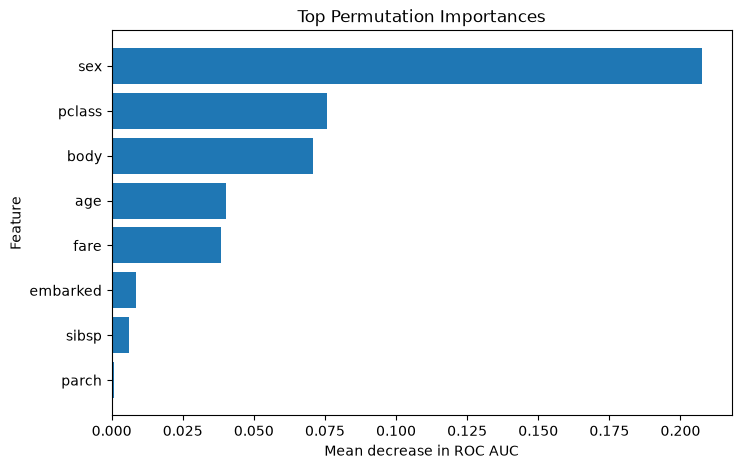

In [70]:
# Plot permutation importance

top_features = importance_df.head(10)

plt.figure(figsize=(8, 5))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Mean decrease in ROC AUC")
plt.ylabel("Feature")
plt.title("Top Permutation Importances")

plt.show()

### Permutation Importance Interpretation

Sex was the most important feature, with a much larger permutation importance than the other variables. Passenger class was the second most important feature, followed by body, age, and fare. Embarked, sibsp, and parch had much smaller effects on ROC AUC. These results suggest that sex and passenger class provided the strongest predictive information for the Boosting model.

## Model Comparison

The models should not be selected using accuracy alone. ROC AUC measures ranking performance, F1 balances precision and recall, and Brier score and log loss evaluate the quality of predicted probabilities. Training time is also considered because a more complicated model should provide enough performance improvement to justify its additional cost.

In [71]:
# Combined comparison

comparison_df = results_df.merge(
    cv_results_df,
    on="Model"
)

display(
    comparison_df.sort_values(
        "ROC AUC Mean",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1,ROC AUC,Log Loss,Brier Score,Training Time,Accuracy Mean,Accuracy SD,F1 Mean,F1 SD,ROC AUC Mean,ROC AUC SD
0,Boosting,0.828244,0.802198,0.73,0.764398,0.913457,0.376387,0.114327,0.157273,0.814366,0.023320,0.742930,0.033010,0.878377,0.030495
1,Random Forest,0.839695,0.829545,0.73,0.776596,0.903426,0.380260,0.115497,0.247136,0.817417,0.027145,0.738121,0.041199,0.867172,0.028449
2,Bagging,0.839695,0.862500,0.69,0.766667,0.904691,0.389370,0.116185,0.209966,0.810544,0.032161,0.727727,0.047844,0.864952,0.033319
3,Voting,0.835878,0.813187,0.74,0.774869,0.895154,0.384488,0.117092,0.090022,0.806721,0.024700,0.733261,0.038507,0.864897,0.023372
4,Logistic Regression,0.809160,0.771739,0.71,0.739583,0.866883,0.433353,0.135343,0.008191,0.788392,0.010612,0.713685,0.020821,0.840851,0.026860
5,Stacking,0.843511,0.831461,0.74,0.783069,0.897623,0.379612,0.114922,0.602764,0.791463,0.017640,0.688522,0.028559,0.821854,0.038434


In [72]:
# Automatically identify the strongest model

best_row = cv_results_df.sort_values(
    "ROC AUC Mean",
    ascending=False
).iloc[0]

baseline_row = cv_results_df[
    cv_results_df["Model"] == "Logistic Regression"
].iloc[0]

print("Recommended model:", best_row["Model"])
print(
    "Best cross-validation ROC AUC:",
    round(best_row["ROC AUC Mean"], 4)
)

print(
    "Logistic regression ROC AUC:",
    round(baseline_row["ROC AUC Mean"], 4)
)

print(
    "ROC AUC improvement:",
    round(
        best_row["ROC AUC Mean"] -
        baseline_row["ROC AUC Mean"],
        4
    )
)

Recommended model: Boosting
Best cross-validation ROC AUC: 0.8784
Logistic regression ROC AUC: 0.8409
ROC AUC improvement: 0.0375


## Final Recommendation

I would select the Boosting model as it had the best cross-validated ROC AUC score (0.878) compared to Random Forest (0.867) and Logistic Regression (0.841). The Boosting Model also had the best Brier Score (0.114) and lowest log loss (0.376) meaning the model predictions were good. The Stacking model had slightly better accuracy and F1 scores on the hold-out data however had a lower ROC AUC score of 0.822 on cross-validation. The Boosting model also took approx 0.16 seconds to train so it seems sensible to add the added complexity. Overall the Boosting model performed best overall with the best balance between prediction accuracy, calibration and consistency and also computational cost.

## Reproducibility

A fixed random seed of 42 is used throughout the experiment. The train/test split is stratified and the cross-validation procedure uses the same fixed random state. Preprocessing is contained inside the model pipelines so that the same transformations can be reproduced during training and inference.

## Leakage Prevention

The target variable is removed before training and preprocessing is fitted only within the training folds. The boat feature is excluded because it contains information that is directly related to whether a passenger survived. Keeping this type of feature would make offline performance look better without representing a valid prediction scenario.

## ML Systems Considerations

Logistic regression has the lowest model complexity and is generally the easiest to deploy and monitor. Ensemble models require more computation and can be harder to interpret, especially when several models are combined. For this dataset, inference latency is unlikely to be a major issue, but training time and model maintenance still matter if the pipeline is retrained frequently.

## Post-Deployment Monitoring

The deployed model should be monitored for changes in feature distributions, missing-value rates, categorical values, prediction distributions, and survival outcomes when labels become available. Performance metrics such as ROC AUC, F1, Brier score, and calibration should be tracked over time. Large changes in feature distributions or a sustained performance decline should trigger an investigation and possible model retraining.

## Rollback Plan

The production system should keep the previous validated model available. If the new model shows a significant performance regression, calibration problem, unexpected feature behavior, or increased operational cost, the system can switch back to the previous model while the issue is investigated. Each model version should be stored with its preprocessing configuration, training data version, evaluation metrics, and random seed.

## Limitations

Overall, this dataset is quite small, and is an example of historical data. This means that the conclusions may not be applicable to transportation data in current times. Some of the variables have missing data and are historical, which would not be available prior to the passenger travelling. As such, these results should be considered as model comparison only.

## Conclusion

This experiment used logistic regression and various ensemble models (voting, bagging, random forest, boosting and stacking) to predict survival on the titanic. Boosting showed the best performance with cross validated ROC AUC of 0.878. It also had the best calibration results. Logistic regression model was much quicker and easier to run however had lower ROC AUC score of 0.841. The ensemble models provided good results to justify the added complexity. Boosting had a significant improvement over the logistic regression model with minimal increase in training time. However, for production use features like body would need removing.